# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- Ноутбук использует полные сплиты. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство Colab T4
- Модель — `google-bert/bert-base-cased`, Apache 2.0 [Карточка модели](https://huggingface.co/google-bert/bert-base-cased)
- Датасет — CoNLL-2003, английские новости Reuters. В карточке лицензия указана как `other`, использование исходных текстов регулируется условиями Reuters [Карточка датасета](https://huggingface.co/datasets/tomaarsen/conll2003#licensing-information)
- Источники — шаблон задания и публикация авторов CoNLL-2003 [Описание корпуса](https://aclanthology.org/W03-0419/)
- Бонусы — 6.1–6.5

In [ ]:
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

In [ ]:
import collections
import json
import math
import random
import re
import time
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from seqeval.metrics.sequence_labeling import get_entities as seqeval_entities
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    Trainer,
    TrainingArguments,
)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(
    f'torch {torch.__version__}, transformers {transformers.__version__}, '
    f'datasets {datasets.__version__}'
)
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [ ]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = (
    torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
)
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [ ]:
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
EPOCHS = 3
MAX_LENGTH = 128
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [ ]:
MODEL_ID = 'google-bert/bert-base-cased'
REVISION = 'cd5ef92a9fb2f889e972770a36d4ed042daf221e'
TOKENIZER_KWARGS = {}

In [ ]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(
    r'[0-9a-f]{40}', REVISION or ''
), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {
    s.rfilename: f'{s.size / 2**20:.0f} MB'
    for s in info.siblings
    if s.rfilename.endswith(('.safetensors', '.bin'))
}
print(
    f'model:    {MODEL_ID}\nrevision: {info.sha}\n'
    f'license:  {card.get("license")}\nlanguage: {card.get("language")}'
)
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS
)
assert (
    tokenizer.is_fast
), 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('European Commission officials met in Brussels'))

model:    google-bert/bert-base-cased
revision: cd5ef92a9fb2f889e972770a36d4ed042daf221e
license:  apache-2.0
language: en
updated:  2024-02-19 11:02:26+00:00
weights:  {'model.safetensors': '416 MB', 'pytorch_model.bin': '416 MB'}
BertTokenizer vocab size 28996
['European', 'Commission', 'officials', 'met', 'in', 'Brussels']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ**

BERT обучен на английских Wikipedia и BookCorpus. У cased-версии
около 109 млн параметров, и она сохраняет регистр. В новостях заглавные
буквы помогают находить имена, хотя в заголовках часто встречается
сплошной верхний регистр. Лицензия модели — Apache 2.0.

BERT base uncased примерно того же размера, но токенизатор приводит
слова к нижнему регистру. DistilBERT base cased меньше, около 66 млн
параметров, поэтому от него можно ожидать более быстрого прогона.
Качество этих вариантов на CoNLL-2003 в этом эксперименте ожидаемое,
фактическое сравнение с ними не проводилось. Фиксация ревизии
защищает от замены весов, конфига и файлов токенизатора на Hub.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [ ]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS
)
cfg = demo_model.config
print(
    {
        k: getattr(cfg, k, None)
        for k in [
            'model_type',
            'vocab_size',
            'hidden_size',
            'num_hidden_layers',
            'num_attention_heads',
            'intermediate_size',
            'max_position_embeddings',
        ]
    }
)
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 28996, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [ ]:
def params_by_block(model):
    backbone = model.base_model
    layers = [
        sum(parameter.numel() for parameter in layer.parameters())
        for layer in backbone.encoder.layer
    ]
    embeddings = sum(
        parameter.numel() for parameter in backbone.embeddings.parameters()
    )
    encoder = sum(layers)
    head = sum(
        parameter.numel() for parameter in model.classifier.parameters()
    )
    total = sum(parameter.numel() for parameter in model.parameters())
    return {
        'embeddings': embeddings,
        'encoder': encoder,
        'head': head,
        'other': total - embeddings - encoder - head,
        'layers': layers,
    }

In [ ]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert (
    sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
)
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert (
    len(blocks['layers']) == cfg.num_hidden_layers
    and sum(blocks['layers']) == blocks['encoder']
), (
    'encoder - сумма слоев, все вне слоев '
    '(например, rel_embeddings у DeBERTa) - в other'
)
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    22,665,216   21.0%
encoder       85,054,464   79.0%
head               5,383    0.0%
other                  0    0.0%
total        107,725,063
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [ ]:
demo_texts = [
    ['The', 'European', 'Commission', 'met', 'in', 'Brussels', '.'],
    ['Peter', 'Blackburn', 'filed', 'a', 'report', '.'],
]
enc = tokenizer(
    demo_texts,
    is_split_into_words=True,
    padding=True,
    return_tensors='pt',
)
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for index, hidden in enumerate(out.hidden_states):
    print(f'hidden_states[{index}]', tuple(hidden.shape))
print('logits', tuple(out.logits.shape))

input_ids (2, 9)
attention_mask (2, 9)
hidden_states[0] (2, 9, 768)
hidden_states[1] (2, 9, 768)
hidden_states[2] (2, 9, 768)
hidden_states[3] (2, 9, 768)
hidden_states[4] (2, 9, 768)
hidden_states[5] (2, 9, 768)
hidden_states[6] (2, 9, 768)
hidden_states[7] (2, 9, 768)
hidden_states[8] (2, 9, 768)
hidden_states[9] (2, 9, 768)
hidden_states[10] (2, 9, 768)
hidden_states[11] (2, 9, 768)
hidden_states[12] (2, 9, 768)
logits (2, 9, 7)


In [ ]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)


x = {
    k: v.to(device)
    for k, v in tokenizer(
        [['news'] * 62] * 32, is_split_into_words=True, return_tensors='pt'
    ).items()
}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
forward_ms = (time.perf_counter() - start) / 5 * 1000
print(
    f'forward 32 x {x["input_ids"].shape[1]}: '
    f'{forward_ms:.1f} ms на {DEVICE_NAME}'
)
demo_model = demo_model.cpu()

forward 32 x 64: 132.9 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ**

Токенизатор готовит `input_ids` и `attention_mask` формы `(2, T)`.
Эмбеддинги и каждый из 12 слоёв BERT выдают `(2, T, 768)`, а
демонстрационная голова возвращает `(2, T, 7)`. Размер `T`
печатается выше. В него входят специальные токены, части слов и
дополнение до длины самого длинного примера в батче. Основная часть
параметров находится в 12 слоях энкодера. Токены обмениваются
информацией внутри этих слоёв, после чего линейная голова
классифицирует каждый токен независимо.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [ ]:
DATASET_ID = 'tomaarsen/conll2003'
DATASET_CONFIG = 'default'
DATASET_REVISION = '3a0c0677d3177b6122fceed3239dda7a5de6a514'

In [ ]:
raw = load_dataset(
    DATASET_ID,
    DATASET_CONFIG,
    revision=DATASET_REVISION,
)
LABEL_NAMES = list(raw['train'].features['ner_tags'].feature.names)
print(raw)
print('BIO tags', LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
BIO tags ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


split         sentences     LOC    MISC     ORG     PER
train            14,041   7,140   3,438   6,321   6,600
validation        3,250   1,837     922   1,341   1,842
test              3,453   1,668     702   1,661   1,617


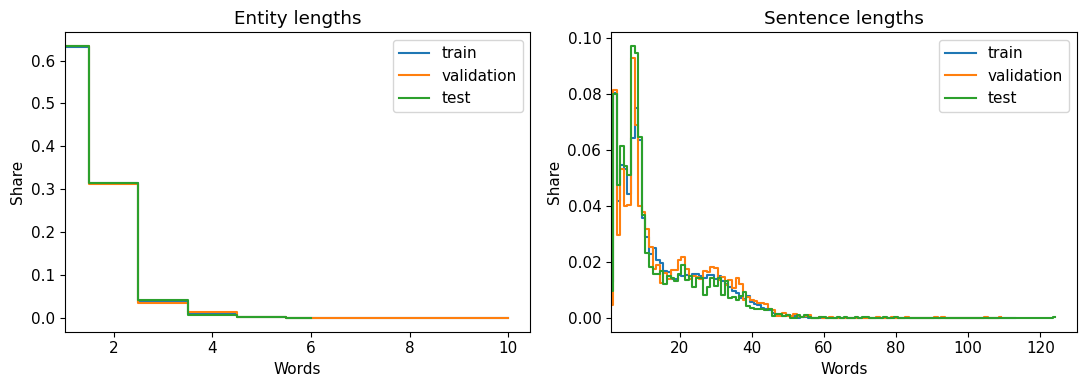

In [ ]:
entity_types = sorted({tag[2:] for tag in LABEL_NAMES if tag != 'O'})
print(
    f"{'split':<12} {'sentences':>10}",
    *[f'{kind:>7}' for kind in entity_types],
)
figure, axes = plt.subplots(1, 2, figsize=(11, 4))

for split, examples in raw.items():
    tag_sequences = [
        [LABEL_NAMES[tag] for tag in tags] for tags in examples['ner_tags']
    ]
    spans_by_sentence = seqeval_entities(tag_sequences)
    counts = collections.Counter(kind for kind, _, _ in spans_by_sentence)
    span_lengths = [end - start + 1 for _, start, end in spans_by_sentence]
    sentence_lengths = [len(words) for words in examples['tokens']]

    print(
        f'{split:<12} {len(examples):>10,}',
        *[f'{counts[kind]:>7,}' for kind in entity_types],
    )
    span_counts = np.bincount(span_lengths)
    sentence_counts = np.bincount(sentence_lengths)
    axes[0].step(
        np.arange(1, len(span_counts)),
        span_counts[1:] / len(span_lengths),
        where='mid',
        label=split,
    )
    axes[1].step(
        np.arange(1, len(sentence_counts)),
        sentence_counts[1:] / len(sentence_lengths),
        where='mid',
        label=split,
    )

for axis, title in zip(axes, ['Entity lengths', 'Sentence lengths']):
    axis.set(title=title, xlabel='Words', ylabel='Share', xlim=(1, None))
    axis.legend()

figure.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ**

Английская часть CoNLL-2003 состоит из новостных текстов Reuters.
Сущности вручную размечали в Университете Антверпена. Сохранены
исходные сплиты: 14 041 предложение в train, 3 250 в validation и
3 453 в test. Четыре типа — `PER`, `ORG`, `LOC` и `MISC`.
В карточке лицензия указана как `other`, а условия использования
исходных текстов определяет Reuters. Статистику сущностей по сплитам
и распределения длин выводит ячейка выше. [Разметка и условия использования](https://huggingface.co/datasets/tomaarsen/conll2003#licensing-information)

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [ ]:
def bio_to_spans(tags):
    spans = []
    start = 0
    active_type = None

    for index, tag in enumerate(tags):
        prefix, _, entity_type = tag.partition('-')
        if prefix == 'I' and entity_type == active_type:
            continue
        if active_type is not None:
            spans.append((start, index, active_type))
        active_type = entity_type if prefix in {'B', 'I'} else None
        start = index

    if active_type is not None:
        spans.append((start, len(tags), active_type))
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, entity_type in spans:
        tags[start] = f'B-{entity_type}'
        tags[start + 1 : end] = [f'I-{entity_type}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels = []
    seen_words = set()

    for word in word_ids:
        if word is None:
            labels.append(-100)
        elif word not in seen_words:
            labels.append(word_labels[word])
            seen_words.add(word)
        elif b_to_i is None:
            labels.append(-100)
        else:
            label = word_labels[word]
            labels.append(b_to_i.get(label, label))

    return labels

In [ ]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [
    (0, 2, 'PER'),
    (3, 4, 'LOC'),
    (4, 6, 'LOC'),
    (7, 8, 'ORG'),
]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [
    (0, 1, 'PER'),
    (1, 3, 'LOC'),
]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert (
    bio_to_spans([]) == []
    and bio_to_spans(['O'] * 3) == []
    and spans_to_bio([], 2) == ['O', 'O']
)

rng = random.Random(0)
for _ in range(2000):
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [
    -100,
    1,
    -100,
    0,
    3,
    -100,
    -100,
    -100,
]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [
    -100,
    1,
    2,
    0,
    3,
    4,
    4,
    -100,
]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [
    -100,
    2,
    2,
    6,
    -100,
]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]
print('ok')

ok


In [ ]:
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)

for split, examples in raw.items():
    spans_path = data_dir / f'{split}_spans.jsonl'
    with spans_path.open('w', encoding='utf-8') as file:
        for example in examples:
            tags = [LABEL_NAMES[tag] for tag in example['ner_tags']]
            row = {'tokens': example['tokens'], 'spans': bio_to_spans(tags)}
            file.write(json.dumps(row, ensure_ascii=False) + '\n')

    normalized = 0
    with spans_path.open(encoding='utf-8') as file:
        for example, line in zip(examples, file, strict=True):
            row = json.loads(line)
            original = [LABEL_NAMES[tag] for tag in example['ner_tags']]
            spans = [tuple(span) for span in row['spans']]
            assert row['tokens'] == example['tokens']
            restored = spans_to_bio(spans, len(row['tokens']))
            assert bio_to_spans(restored) == bio_to_spans(original)
            normalized += restored != original

    print(
        f'{split}: проверено {len(examples):,}, '
        f'нормализовано BIO {normalized:,}'
    )

train: проверено 14,041, нормализовано BIO 0
validation: проверено 3,250, нормализовано BIO 0
test: проверено 3,453, нормализовано BIO 0


In [ ]:
assert isinstance(raw, DatasetDict) and isinstance(
    LABEL_NAMES, list
), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(
    raw
), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(
    re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES
), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {
    label2id[t]: label2id['I-' + t[2:]]
    for t in LABEL_NAMES
    if t.startswith('B-') and 'I-' + t[2:] in label2id
}


data = raw


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(
        batch['tokens'],
        is_split_into_words=True,
        truncation=True,
        max_length=MAX_LENGTH,
    )
    enc['labels'] = [
        align_labels(
            tags, enc.word_ids(i), B_TO_I if label_all_subwords else None
        )
        for i, tags in enumerate(batch['ner_tags'])
    ]
    return enc


tokenized = data.map(
    tokenize_and_align, batched=True, remove_columns=data['train'].column_names
)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)


alignment_stats = {}

for split, examples in data.items():
    truncated = 0
    lost_words = 0
    checked = 0

    for example in examples.iter(batch_size=256):
        full = tokenizer(example['tokens'], is_split_into_words=True)
        encoded = tokenizer(
            example['tokens'],
            is_split_into_words=True,
            truncation=True,
            max_length=MAX_LENGTH,
        )
        for index, (words, tags) in enumerate(
            zip(example['tokens'], example['ner_tags'], strict=True)
        ):
            word_ids = encoded.word_ids(index)
            aligned = align_labels(tags, word_ids)
            got = {
                word: label
                for word, label in zip(word_ids, aligned, strict=True)
                if label != -100
            }
            assert got == {word: tags[word] for word in set(word_ids) - {None}}

            truncated += len(full['input_ids'][index]) > MAX_LENGTH
            lost_words += len(words) - len(got)
            if len(got) == len(words):
                restored = [
                    LABEL_NAMES[got[word]] for word in range(len(words))
                ]
                assert bio_to_spans(restored) == bio_to_spans(
                    [LABEL_NAMES[tag] for tag in tags]
                )
                checked += 1

    alignment_stats[split] = {
        'checked': checked,
        'truncated': truncated,
        'lost_words': lost_words,
    }
    print(
        f'{split}: проверено {checked:,}, обрезано {truncated:,}, '
        f'слов без сабвордов или за обрезкой {lost_words:,}'
    )

ex = data['train'][0]
enc = tokenizer(
    ex['tokens'],
    is_split_into_words=True,
    truncation=True,
    max_length=MAX_LENGTH,
)
for subword, word, label in zip(
    enc.tokens(),
    enc.word_ids(),
    align_labels(ex['ner_tags'], enc.word_ids()),
    strict=True,
):
    displayed_label = LABEL_NAMES[label] if label != -100 else -100
    print(f'{subword:<16}{str(word):>5}  {displayed_label}')

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 14,040, обрезано 1, слов без сабвордов или за обрезкой 28
validation: проверено 3,246, обрезано 4, слов без сабвордов или за обрезкой 39
test: проверено 3,451, обрезано 2, слов без сабвордов или за обрезкой 18
[CLS]            None  -100
EU                  0  B-ORG
rejects             1  O
German              2  B-MISC
call                3  O
to                  4  O
boycott             5  O
British             6  B-MISC
la                  7  O
#

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ**

По умолчанию loss использует только первый сабворд слова. Если
включить все части, слова с длинным разбиением внесут в loss больший
вклад. Метку `-100` cross-entropy пропускает, поэтому специальные
токены и продолжения слова не влияют на градиент. Для слов за
границей `MAX_LENGTH` декодер возвращает `O`, и потеря хвоста может
привести к пропускам или ошибкам границ. Итоги проверки по сплитам
выведены выше.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [ ]:
@torch.no_grad()
def predict_word_tags(
    model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None
):

    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start : start + batch_size]
        enc = tok(
            batch,
            is_split_into_words=True,
            truncation=True,
            max_length=MAX_LENGTH,
            padding=True,
            return_tensors='pt',
        )
        probs = (
            model(**{k: v.to(dev) for k, v in enc.items()})
            .logits.float()
            .softmax(-1)
            .cpu()
        )
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = (
                ['O'] * len(words),
                [1.0] * len(words),
                set(),
            )
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[
                    int(best[i, pos])
                ], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(
        f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
        f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
        precision=precision_score(gold, pred, zero_division=0),
        recall=recall_score(gold, pred, zero_division=0),
    )


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID,
        revision=revision or REVISION,
        num_labels=len(LABEL_NAMES),
        id2label=id2label,
        label2id=label2id,
    )


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [
    [LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']
]

In [ ]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: tags.most_common(1)[0][0] for word, tags in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [ ]:
toy_tokens = [
    ['Анна', 'живет', 'в', 'Москве'],
    ['Москве', 'не', 'до', 'сна'],
    ['Анна', 'Каренина'],
    ['в', 'Москве'],
]
toy_tags = [
    ['B-PER', 'O', 'O', 'B-LOC'],
    ['B-LOC', 'O', 'O', 'O'],
    ['B-PER', 'I-PER'],
    ['O', 'B-ORG'],
]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert (
    toy['Москве'] == 'B-LOC'
    and toy['Анна'] == 'B-PER'
    and toy['Каренина'] == 'I-PER'
)
assert (
    fit_majority_tagger(
        [['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']]
    )['Ленина']
    == 'B-PER'
)
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == [
    'B-PER',
    'O',
    'B-LOC',
]
assert predict_majority(toy, []) == []

train_tags = [
    [LABEL_NAMES[tag] for tag in tags] for tags in data['train']['ner_tags']
]
majority = fit_majority_tagger(data['train']['tokens'], train_tags)
majority_pred = [predict_majority(majority, words) for words in val_tokens]

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
del random_model

baseline = {
    'majority': entity_scores(val_gold, majority_pred),
    'random_head': entity_scores(val_gold, random_pred),
}
for name, scores in baseline.items():
    print(f"{name}: micro F1 {scores['f1_micro']:.4f}")

random_tags = collections.Counter(tag for tags in random_pred for tag in tags)
print('Частые теги случайной головы', random_tags.most_common(5))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

majority: micro F1 0.6536
random_head: micro F1 0.0356
Частые теги случайной головы [('B-ORG', 21915), ('B-MISC', 7989), ('B-PER', 7424), ('I-MISC', 4519), ('B-LOC', 3455)]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ**

Словарь может правильно размечать повторяющиеся имена и географические
названия. Для незнакомых слов он ставит `O`, а для знакомых не
учитывает контекст, поэтому один и тот же вариант слова всегда
получает одинаковую метку. У предобученного BERT есть контекстные
представления, но веса случайной головы ещё не связывают их с
BIO-тегами. Фактические F1 и частые теги случайной головы выводятся
выше.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [ ]:
LR = 3e-5
BATCH_SIZE = 16


def train_ner(
    model,
    train_ds,
    eval_ds,
    epochs=EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    freeze_encoder=False,
    tok=None,
    out_dir='runs/main',
):
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)

    gpu_count = max(1, torch.cuda.device_count())
    steps = math.ceil(len(train_ds) / (batch_size * gpu_count)) * epochs
    eval_interval = max(1, steps // 10)
    args = TrainingArguments(
        output_dir=out_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        num_train_epochs=epochs,
        warmup_steps=math.ceil(steps * 0.1),
        weight_decay=0.01,
        fp16=device.type == 'cuda',
        logging_strategy='steps',
        logging_steps=eval_interval,
        eval_strategy='steps',
        eval_steps=eval_interval,
        save_strategy='no',
        report_to='none',
        seed=SEED,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=DataCollatorForTokenClassification(tok),
        processing_class=tok,
    )
    started = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - started
    trainer.accelerator.unwrap_model(model, keep_fp32_wrapper=False)
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.6026', 'grad_norm': '3.387', 'learning_rate': '2.977e-05', 'epoch': '0.2995'}
{'eval_loss': '0.09828', 'eval_runtime': '7.075', 'eval_samples_per_second': '459.4', 'eval_steps_per_second': '28.83', 'epoch': '0.2995'}
{'loss': '0.06901', 'grad_norm': '1.199', 'learning_rate': '2.67e-05', 'epoch': '0.5991'}
{'eval_loss': '0.06308', 'eval_runtime': '8.546', 'eval_samples_per_second': '380.3', 'eval_steps_per_second': '23.87', 'epoch': '0.5991'}
{'loss': '0.05464', 'grad_norm': '0.9535', 'learning_rate': '2.337e-05', 'epoch': '0.8986'}
{'eval_loss': '0.04207', 'eval_runtime': '4.143', 'eval_samples_per_second': '784.4', 'eval_steps_per_second': '49.24', 'epoch': '0.8986'}
{'loss': '0.03508', 'grad_norm': '0.5225', 'learning_rate': '2.004e-05', 'epoch': '1.198'}
{'eval_loss': '0.0396', 'eval_runtime': '3.629', 'eval_samples_per_second': '895.6', 'eval_steps_per_second': '56.22', 'epoch': '1.198'}
{'loss': '0.02583', 'grad_norm': '1.739', 'learning_rate': '1.671e-05', 'epoch': '1

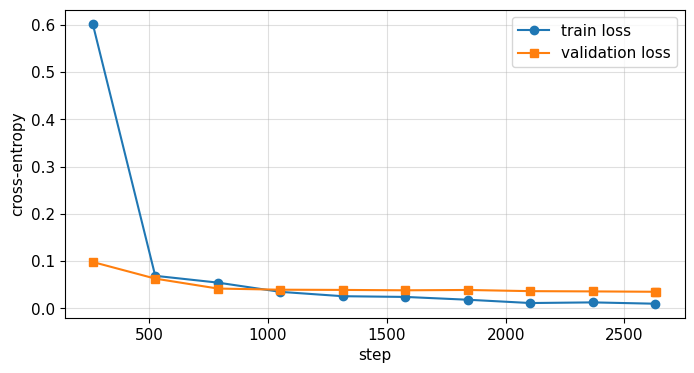

In [ ]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(
    model, tokenized['train'], tokenized['validation']
)
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert (
    len(train_curve) >= 2 and len(eval_curve) >= 2
), 'логируйте train и eval loss по ходу обучения'
print(
    f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, '
    f'{len(tokenized["train"])} предложений, {EPOCHS} эпох(а)'
)

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ**

Learning rate `3e-5` позволяет дообучать базовый BERT небольшими
шагами. Батч из 16 предложений ограничивает расход памяти на T4.
В полном режиме модель обучается три эпохи, первые 10% шагов
отведены под warmup. Используются weight decay `0.01` и FP16 на
CUDA. Время обучения и устройство печатаются над графиком. После
прогона по кривым нужно проверить, продолжает ли падать
validation loss к концу обучения.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [ ]:
def token_f1(gold, pred):
    gold_count = 0
    pred_count = 0
    matches = 0

    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for gold_tag, pred_tag in zip(gold_tags, pred_tags, strict=True):
            gold_count += gold_tag != 'O'
            pred_count += pred_tag != 'O'
            matches += pred_tag != 'O' and gold_tag == pred_tag

    denominator = gold_count + pred_count
    return 2 * matches / denominator if denominator else 0.0

In [ ]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9
assert abs(f1_score(g, p) - 0.5) < 1e-9
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(words) for words in data['test']['tokens']]
test_gold = [
    [LABEL_NAMES[tag] for tag in tags] for tags in data['test']['ner_tags']
]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)


def evaluate_split(name, gold, pred):
    print(name)
    print(classification_report(gold, pred, digits=4, zero_division=0))
    scores = entity_scores(gold, pred)
    scores['token_f1'] = token_f1(gold, pred)
    report = classification_report(
        gold, pred, output_dict=True, zero_division=0
    )
    scores['per_type'] = {
        kind: report[kind] for kind in ENTITY_TYPES if kind in report
    }
    print(f"Token F1 {scores['token_f1']:.4f}")
    return scores


val_scores = evaluate_split('Validation', val_gold, val_pred)
final = evaluate_split('Test', test_gold, test_pred)
model.to('cpu')

Validation
              precision    recall  f1-score   support

         LOC     0.9674    0.9690    0.9682      1837
        MISC     0.8930    0.9143    0.9035       922
         ORG     0.9320    0.9306    0.9313      1341
         PER     0.9703    0.9739    0.9721      1842

   micro avg     0.9486    0.9534    0.9510      5942
   macro avg     0.9407    0.9470    0.9438      5942
weighted avg     0.9488    0.9534    0.9510      5942

Token F1 0.9596
Test
              precision    recall  f1-score   support

         LOC     0.9335    0.9341    0.9338      1668
        MISC     0.7785    0.8162    0.7969       702
         ORG     0.8820    0.9043    0.8930      1661
         PER     0.9575    0.9610    0.9593      1617

   micro avg     0.9051    0.9184    0.9117      5648
   macro avg     0.8879    0.9039    0.8957      5648
weighted avg     0.9060    0.9184    0.9121      5648

Token F1 0.9247


BertForTokenClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(28996, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), ep

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ**

Micro F1 учитывает все сущности вместе, поэтому частые типы сильнее
влияют на результат. Macro F1 усредняет F1 по типам. Токенный F1
даёт частичный зачёт, если модель верно пометила только часть
сущности. Например, при разметке `European Commission` как
организации попадание только в `European` даёт одно верное слово,
но теряет сущность целиком. Для получения готовых имён и названий
важнее F1 по сущностям. Какой тип оказался самым трудным и насколько
разошлись метрики, видно в отчётах выше.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [ ]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    results = []
    overlapping = set()

    for gold in gold_spans:
        matches = []
        for index, pred in enumerate(pred_spans):
            overlap = min(gold[1], pred[1]) - max(gold[0], pred[0])
            if overlap > 0:
                overlapping.add(index)
                matches.append((pred, overlap))

        if not matches:
            results.append(('missed', gold, None))
            continue

        pred, _ = max(
            matches,
            key=lambda match: (
                match[0] == gold,
                match[0][2] == gold[2],
                match[1],
            ),
        )
        if pred == gold:
            category = 'correct'
        elif pred[2] == gold[2]:
            category = 'boundary'
        else:
            category = 'type'
        results.append((category, gold, pred))

    for index, pred in enumerate(pred_spans):
        if index not in overlapping:
            results.append(('spurious', None, pred))
    return results

In [ ]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {
    'correct': 1,
    'boundary': 1,
    'type': 1,
    'missed': 1,
    'spurious': 1,
}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and (
    'spurious',
    None,
    (13, 14, 'ORG'),
) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and (
    'missed',
    (11, 12, 'PER'),
    None,
) in res
assert categorize_errors([], []) == [] and categorize_errors(
    [], [(0, 1, 'PER')]
) == [('spurious', None, (0, 1, 'PER'))]
assert [
    c
    for c, _, _ in categorize_errors(
        [(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')]
    )
] == ['boundary']
assert [
    c
    for c, _, _ in categorize_errors(
        [(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')]
    )
] == ['boundary', 'boundary']
assert sorted(
    c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])
) == ['missed', 'spurious']

counts = collections.Counter()
error_examples = collections.defaultdict(list)

for words, gold_tags, pred_tags in zip(
    val_tokens, val_gold, val_pred, strict=True
):
    for category, gold, pred in categorize_errors(
        bio_to_spans(gold_tags),
        bio_to_spans(pred_tags),
    ):
        counts[category] += 1
        if category != 'correct' and len(error_examples[category]) < 5:
            error_examples[category].append((words, gold, pred))

errors = {category: counts[category] for category in ERROR_CATEGORIES}
total_errors = sum(errors.values()) - errors['correct']
print(f"correct: {errors['correct']:,}")
for category in ERROR_CATEGORIES[1:]:
    share = errors[category] / total_errors if total_errors else 0.0
    print(f'{category}: {errors[category]:,} ({share:.1%})')


def show_span(words, span):
    if span is None:
        return '—'
    start, end, kind = span
    return f"{' '.join(words[start:end])} [{kind}]"


for category, examples in error_examples.items():
    for words, gold, pred in examples:
        print(f'\n{category}: {" ".join(words)}')
        print('  gold', show_span(words, gold))
        print('  pred', show_span(words, pred))

correct: 5,665
boundary: 73 (21.6%)
type: 150 (44.4%)
missed: 54 (16.0%)
spurious: 61 (18.0%)

type: CRICKET - LEICESTERSHIRE TAKE OVER AT TOP AFTER INNINGS VICTORY .
  gold LEICESTERSHIRE [ORG]
  pred LEICESTERSHIRE [PER]

type: SOCCER - ROTOR FANS LOCKED OUT AFTER VOLGOGRAD VIOLENCE .
  gold VOLGOGRAD [LOC]
  pred VOLGOGRAD [MISC]

type: BOXING - PANAMA 'S ROBERTO DURAN FIGHTS THE SANDS OF TIME .
  gold PANAMA [LOC]
  pred PANAMA [PER]

type: If he loses Saturday , it could devalue his position as one of the world 's great boxers , " Panamanian Boxing Association President Ramon Manzanares said .
  gold Panamanian [MISC]
  pred Panamanian Boxing Association [ORG]

type: O'Brien , a winner two weeks ago in New Haven for his first pro title , served for the match at 5-4 in the third set before Washington came charging back .
  gold Washington [PER]
  pred Washington [LOC]

missed: They were held up by a gritty 84 from Paul Johnson but ex-England fast bowler Martin McCague took four for

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ**

При разборе примеров стоит отдельно проверить сокращения, имена из
нескольких слов и случаи, где название команды совпадает с названием
города. После прогона нужно указать самую частую категорию, её долю и
объяснить по выведенным примерам, где ошиблась модель и где
неоднозначна разметка.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [ ]:
ABLATION = 'freeze'
assert ABLATION in {'freeze', 'all_subwords'}

if ABLATION == 'all_subwords':
    ablation_data = data.map(
        tokenize_and_align,
        batched=True,
        remove_columns=data['train'].column_names,
        fn_kwargs={'label_all_subwords': True},
    )
else:
    ablation_data = tokenized

set_seed(SEED)
ablation_model = make_model()
_, ablation_seconds = train_ner(
    ablation_model,
    ablation_data['train'],
    ablation_data['validation'],
    freeze_encoder=ABLATION == 'freeze',
    out_dir='runs/ablation',
)
ablation_pred = predict_word_tags(ablation_model, val_tokens)
ablation = {
    'setting': ABLATION,
    'main': {
        **val_scores,
        'train_seconds': train_seconds,
        'trainable_params': sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        ),
    },
    'variant': {
        **entity_scores(val_gold, ablation_pred),
        'token_f1': token_f1(val_gold, ablation_pred),
        'train_seconds': ablation_seconds,
        'trainable_params': sum(
            parameter.numel()
            for parameter in ablation_model.parameters()
            if parameter.requires_grad
        ),
    },
}
for name in ('main', 'variant'):
    scores = ablation[name]
    print(
        f"{name}: micro F1 {scores['f1_micro']:.4f}, "
        f"training {scores['train_seconds']:.1f} s, "
        f"trainable parameters {scores['trainable_params']:,}"
    )
del ablation_model

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '2.21', 'grad_norm': '6.877', 'learning_rate': '2.977e-05', 'epoch': '0.2995'}
{'eval_loss': '1.828', 'eval_runtime': '3.387', 'eval_samples_per_second': '959.7', 'eval_steps_per_second': '60.24', 'epoch': '0.2995'}
{'loss': '1.464', 'grad_norm': '3.692', 'learning_rate': '2.67e-05', 'epoch': '0.5991'}
{'eval_loss': '1.11', 'eval_runtime': '3.388', 'eval_samples_per_second': '959.2', 'eval_steps_per_second': '60.21', 'epoch': '0.5991'}
{'loss': '0.9477', 'grad_norm': '2.365', 'learning_rate': '2.337e-05', 'epoch': '0.8986'}
{'eval_loss': '0.8036', 'eval_runtime': '3.525', 'eval_samples_per_second': '922.1', 'eval_steps_per_second': '57.88', 'epoch': '0.8986'}
{'loss': '0.7001', 'grad_norm': '0.8412', 'learning_rate': '2.004e-05', 'epoch': '1.198'}
{'eval_loss': '0.6814', 'eval_runtime': '4.062', 'eval_samples_per_second': '800.1', 'eval_steps_per_second': '50.23', 'epoch': '1.198'}
{'loss': '0.6156', 'grad_norm': '0.7356', 'learning_rate': '1.671e-05', 'epoch': '1.498'}
{'eval

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ**

В эксперименте `freeze` обучается только классификатор. В обеих
конфигурациях используются одни и те же данные, seed, learning rate
и число эпох. Validation F1, время обучения и число обучаемых
параметров сравниваются в выводе выше. Для более надёжного вывода
эксперимент можно повторить с несколькими seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ**

Заполнить после финального прогона. Сравнить validation F1 словаря,
случайной головы и дообученной модели. Указать test micro и macro F1,
самую частую ошибку и результат абляции по F1 и времени. Описать
ограничение эксперимента и следующий шаг.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json` с результатами на полных сплитах. Сдайте файл вместе с ноутбуком.

In [ ]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp',
    model=MODEL_ID,
    revision=REVISION,
    dataset=(
        f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID)
    ),
    classes=ENTITY_TYPES,
    n_train=len(data['train']),
    n_val=len(data['validation']),
    n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline,
    final=final,
    ablation=ablation,
    errors=errors,
    validation=val_scores,
    dataset_revision=DATASET_REVISION,
    device=DEVICE_NAME,
    train_time_sec=RUN_TIMES.get('train_main_sec'),
    fast_mode=False,
)
for key in [
    'f1_micro',
    'f1_macro',
    'precision',
    'recall',
    'token_f1',
    'per_type',
]:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(
    json.dumps(json_ready(metrics), ensure_ascii=False, indent=2),
    encoding='utf-8',
)
print(
    json.dumps(
        json_ready(
            {
                k: v
                for k, v in metrics.items()
                if k not in ('final', 'baseline')
            }
        ),
        ensure_ascii=False,
    )[:600]
)
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google-bert/bert-base-cased", "revision": "cd5ef92a9fb2f889e972770a36d4ed042daf221e", "dataset": "tomaarsen/conll2003/default", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 14041, "n_val": 3250, "n_test": 3453, "params_total": 107726601, "ablation": {"setting": "freeze", "main": {"f1_micro": 0.9509820379385597, "f1_macro": 0.9437887816155694, "precision": 0.9485934360348292, "recall": 0.9533826994278021, "token_f1": 0.9596417771574784, "per_type": {"LOC": {"precision": 0.967391304347826, "recall": 0.9689711486118672, "f1-score": 0.9681805819961925, "support":
final F1 micro 0.9117


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [ ]:
bonus_results = {}


@torch.no_grad()
def forward_ms(network, batch, dev, repeats=10):
    network.eval().to(dev)

    for _ in range(3):
        network(**batch)
    if dev.type == 'cuda':
        torch.cuda.synchronize(dev)

    started = time.perf_counter()
    for _ in range(repeats):
        network(**batch)
    if dev.type == 'cuda':
        torch.cuda.synchronize(dev)
    return (time.perf_counter() - started) * 1000 / repeats


if '6.1' in BONUS_TASKS:
    annotated_news = (
        (
            "[PER|Lena Hart] opened [ORG|Harbor Rail] 's new terminal in "
            '[LOC|Bristol] on Monday .'
        ),
        (
            '[ORG|Northshore Energy] will build two wind farms near '
            '[LOC|Aberdeen] .'
        ),
        (
            '[ORG|Orion Foods] cut its forecast after sales slowed in '
            '[LOC|Canada] .'
        ),
        (
            '[PER|Daniel Reed] was named finance chief of [ORG|Meridian '
            'Bank] .'
        ),
        (
            '[ORG|Cedar Motors] will move its assembly line from '
            '[LOC|Leeds] to [LOC|York] .'
        ),
        (
            '[ORG|Beacon Shipping] opened a route between [LOC|Oslo] and '
            '[LOC|Rotterdam] .'
        ),
        (
            '[PER|Rosa Vega] said [ORG|Sierra Textiles] would add 80 jobs '
            'in [LOC|Madrid] .'
        ),
        (
            '[ORG|Horizon Telecom] signed a contract with [ORG|Pine '
            'Systems] .'
        ),
        '[ORG|Lakeview Markets] bought three stores in [LOC|Dundee] .',
        (
            '[ORG|Westbridge Steel] reported stronger demand from '
            '[MISC|German] manufacturers .'
        ),
        '[PER|Mark Ellis] left [ORG|Ridge Capital] after seven years .',
        (
            '[ORG|Summit Logistics] tested a shorter delivery route through '
            '[LOC|Belgium] .'
        ),
        (
            '[ORG|Bluewater Foods] will close its oldest warehouse in '
            '[LOC|Liverpool] .'
        ),
        (
            '[PER|Maya Collins] scored twice as [ORG|Bristol City] defeated '
            '[ORG|Cardiff City] .'
        ),
        (
            '[ORG|Leeds United] signed [PER|Tom Ward] ahead of the [MISC|FA '
            'Cup] match .'
        ),
        (
            '[PER|Nora Silva] will represent [LOC|Portugal] at the '
            'tournament .'
        ),
        (
            '[ORG|Ajax] will play [ORG|Celtic] in [LOC|Amsterdam] next week '
            '.'
        ),
        (
            '[PER|Evan Clarke] set a course record at the [MISC|Boston '
            'Marathon] .'
        ),
        '[ORG|Real Madrid] drew with [ORG|Valencia] on Sunday .',
        (
            '[PER|Sofia Novak] won the [MISC|Wimbledon] qualifying match in '
            'three sets .'
        ),
        (
            '[ORG|Everton] appointed [PER|Anna Bell] as its academy '
            'director .'
        ),
        '[PER|Mila Weber] joined the [MISC|Swiss] training squad .',
        (
            '[ORG|Roma] reached the final after beating [ORG|Torino] in '
            'extra time .'
        ),
        (
            '[PER|Jonas Berg] carried the flag for [LOC|Norway] at the '
            'opening ceremony .'
        ),
        (
            '[ORG|Brighton] trained in [LOC|Brighton] before the away match '
            '.'
        ),
        (
            '[ORG|FIFA] published the schedule for the [MISC|World Cup] '
            'qualifiers .'
        ),
        (
            '[PER|Iris Lane] briefed the [ORG|European Commission] in '
            '[LOC|Brussels] .'
        ),
        '[ORG|UNICEF] opened a distribution centre in [LOC|Nairobi] .',
        (
            '[PER|Omar Haddad] presented the transport plan to the '
            '[ORG|City Council of Dublin] .'
        ),
        '[ORG|Bank of England] left its main interest rate unchanged .',
        (
            '[ORG|United Nations] officials arrived in [LOC|Geneva] on '
            'Tuesday .'
        ),
        (
            '[PER|Clara Rossi] welcomed the [MISC|French] delegation to '
            '[LOC|Rome] .'
        ),
        (
            '[ORG|Ministry of Health] issued new guidance for hospitals in '
            '[LOC|Malta] .'
        ),
        (
            '[ORG|European Parliament] heard testimony from [PER|Martin '
            'Cole] .'
        ),
        '[PER|David Park] met regional leaders in [LOC|Seoul] .',
        (
            '[ORG|World Health Organization] sent a medical team to '
            '[LOC|Kenya] .'
        ),
        (
            '[PER|Helen Brooks] addressed a crowd outside the station in '
            '[LOC|Oxford] .'
        ),
        '[LOC|Ireland] and [LOC|Spain] agreed to share weather data .',
        (
            '[PER|Ruth Grant] welcomed [MISC|Canadian] observers to '
            '[LOC|Liverpool] .'
        ),
        (
            '[ORG|University of Manchester] published a study led by '
            '[PER|Alice Shah] .'
        ),
        (
            '[ORG|BBC] aired an interview with [PER|Dana Moore] in '
            '[LOC|London] .'
        ),
        (
            '[ORG|British Museum] loaned two objects to an exhibition in '
            '[LOC|Athens] .'
        ),
        (
            '[ORG|Cedar Press] will publish a new translation by [PER|Evan '
            'Liu] .'
        ),
        (
            '[ORG|British Library] received a collection of [MISC|Italian] '
            'maps .'
        ),
        (
            '[ORG|University of Glasgow] invited [PER|Mina Rao] to give the '
            'annual lecture .'
        ),
        (
            '[PER|Lucia Moretti] won the [MISC|Booker Prize] at a ceremony '
            'in [LOC|London] .'
        ),
        ('[ORG|North Coast Orchestra] announced a tour of [LOC|Denmark] ' '.'),
        (
            '[ORG|Associated Press] interviewed [PER|Aisha Khan] in '
            '[LOC|Berlin] .'
        ),
        (
            '[ORG|University of Edinburgh] will host a workshop on '
            '[MISC|Dutch] archives .'
        ),
        (
            '[ORG|Royal Society] invited [PER|Samuel Fox] to speak about '
            'coastal surveys .'
        ),
        (
            '[PER|Nina Cruz] accepted the award for her reporting in '
            '[LOC|Lisbon] .'
        ),
        (
            '[ORG|Northern Film Archive] restored several [MISC|Polish] '
            'newsreels .'
        ),
    )
    marker = re.compile(r'\[(PER|ORG|LOC|MISC)\|([^\]]+)\]|(\S+)')
    extra_rows = []
    for line in annotated_news:
        words = []
        spans = []
        for match in marker.finditer(line):
            kind, phrase, word = match.groups()
            if kind:
                start = len(words)
                words.extend(phrase.split())
                spans.append((start, len(words), kind))
            else:
                words.append(word)

        tags = spans_to_bio(spans, len(words))
        assert bio_to_spans(tags) == spans
        extra_rows.append(
            {'tokens': words, 'ner_tags': [label2id[tag] for tag in tags]}
        )

    assert len(extra_rows) >= 50
    extra_path = Path('extra/conll2003_news_test.jsonl')
    extra_path.parent.mkdir(exist_ok=True)
    with extra_path.open('w', encoding='utf-8') as file:
        for row in extra_rows:
            file.write(json.dumps(row, ensure_ascii=False) + '\n')

    extra_test = load_dataset(
        'json', data_files={'test': str(extra_path)}, split='test'
    )
    extra_gold = [
        [LABEL_NAMES[tag] for tag in tags] for tags in extra_test['ner_tags']
    ]
    extra_pred = predict_word_tags(model, extra_test['tokens'])
    extra_scores = evaluate_split(
        'Дополнительный тест', extra_gold, extra_pred
    )
    extra_delta = extra_scores['f1_micro'] - final['f1_micro']
    bonus_results['6.1'] = {
        'n_sentences': len(extra_test),
        'reference_test_f1': final['f1_micro'],
        'extra_test': extra_scores,
        'delta_f1': extra_delta,
    }

    print(f'Предложений {len(extra_test)}')
    print(f'Изменение micro F1 относительно CoNLL test {extra_delta:+.4f}')

Generating test split: 0 examples [00:00, ? examples/s]

Дополнительный тест
              precision    recall  f1-score   support

         LOC     0.9697    1.0000    0.9846        32
        MISC     0.9167    0.9167    0.9167        12
         ORG     1.0000    1.0000    1.0000        45
         PER     1.0000    1.0000    1.0000        27

   micro avg     0.9829    0.9914    0.9871       116
   macro avg     0.9716    0.9792    0.9753       116
weighted avg     0.9830    0.9914    0.9871       116

Token F1 0.9948
Предложений 52
Изменение micro F1 относительно CoNLL test +0.0754


**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ**

Для отдельного теста размечены 52 авторских предложения в стиле
деловых, спортивных, общественных и культурных новостей. Время
разметки отдельно не замерялось. Выделялись полные имена людей,
организаций и мест, а к `MISC` относились, например, названия
турниров и прилагательные национальности. В «Brighton trained in
Brighton» первое упоминание размечено как команда (`ORG`), второе
как город (`LOC`). В названии организации с городом внутри
оставлялась одна внешняя сущность.

Модель обучается на исходном CoNLL‑2003. Вывод над этой ячейкой
показывает F1 на дополнительном наборе и разницу с исходным test.
Дополнительный набор небольшой и составлен вручную, поэтому
разница зависит от выбранных примеров

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [ ]:
if '6.2' in BONUS_TASKS:
    distil_id = 'distilbert/distilbert-base-cased'
    distil_revision = '6ea81172465e8b0ad3fddeed32b986cdcdcffcf0'
    distil_tokenizer = AutoTokenizer.from_pretrained(
        distil_id, revision=distil_revision
    )
    assert distil_tokenizer.is_fast
    distil_data = data.map(
        tokenize_and_align,
        batched=True,
        remove_columns=data['train'].column_names,
        fn_kwargs={'tok': distil_tokenizer},
    )

    model.to('cpu')
    set_seed(SEED)
    distil_model = make_model(distil_id, distil_revision)
    _, distil_seconds = train_ner(
        distil_model,
        distil_data['train'],
        distil_data['validation'],
        tok=distil_tokenizer,
        out_dir='runs/distilbert',
    )
    distil_pred = predict_word_tags(
        distil_model, test_tokens, tok=distil_tokenizer
    )
    distil_scores = evaluate_split('DistilBERT test', test_gold, distil_pred)
    sample_words = val_tokens[:16]

    bonus_results['6.2'] = {'device': DEVICE_NAME, 'models': {}}
    for name, revision, network, tok, scores, seconds in (
        (MODEL_ID, REVISION, model, tokenizer, final, train_seconds),
        (
            distil_id,
            distil_revision,
            distil_model,
            distil_tokenizer,
            distil_scores,
            distil_seconds,
        ),
    ):
        batch = tok(
            sample_words,
            is_split_into_words=True,
            padding='max_length',
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors='pt',
        ).to(device)
        latency = forward_ms(network, batch, device)
        params = sum(parameter.numel() for parameter in network.parameters())
        size_mib = (
            sum(
                parameter.numel() * parameter.element_size()
                for parameter in network.parameters()
            )
            / 2**20
        )
        bonus_results['6.2']['models'][name] = {
            'revision': revision,
            'test_f1': scores['f1_micro'],
            'train_seconds': seconds,
            'batch_forward_ms': latency,
            'params': params,
            'parameter_mib': size_mib,
        }
        print(
            f"{name}: F1 {scores['f1_micro']:.4f}, "
            f'train {seconds:.1f} s, forward {latency:.2f} ms, '
            f'{params:,} параметров, {size_mib:.1f} MiB'
        )
        network.to('cpu')

    del network, distil_model

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '0.6387', 'grad_norm': '1.348', 'learning_rate': '2.977e-05', 'epoch': '0.2995'}
{'eval_loss': '0.1317', 'eval_runtime': '1.947', 'eval_samples_per_second': '1670', 'eval_steps_per_second': '104.8', 'epoch': '0.2995'}
{'loss': '0.09187', 'grad_norm': '1.657', 'learning_rate': '2.67e-05', 'epoch': '0.5991'}
{'eval_loss': '0.07285', 'eval_runtime': '1.995', 'eval_samples_per_second': '1629', 'eval_steps_per_second': '102.3', 'epoch': '0.5991'}
{'loss': '0.06593', 'grad_norm': '1.994', 'learning_rate': '2.337e-05', 'epoch': '0.8986'}
{'eval_loss': '0.05959', 'eval_runtime': '1.937', 'eval_samples_per_second': '1678', 'eval_steps_per_second': '105.3', 'epoch': '0.8986'}
{'loss': '0.04331', 'grad_norm': '0.5626', 'learning_rate': '2.004e-05', 'epoch': '1.198'}
{'eval_loss': '0.05424', 'eval_runtime': '1.973', 'eval_samples_per_second': '1647', 'eval_steps_per_second': '103.4', 'epoch': '1.198'}
{'loss': '0.03561', 'grad_norm': '1.574', 'learning_rate': '1.671e-05', 'epoch': '1.498'

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ**

BERT и DistilBERT обучаются с одинаковыми сплитами, seed, числом
эпох, learning rate и размером батча. Для каждой модели
используется её токенизатор. Время прямого прохода измеряется
на одних и тех же 16 предложениях с одинаковым паддингом.
Объём в MiB относится к параметрам модели. Сравнение
test F1, времени и размера выводится выше

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [ ]:
if '6.3' in BONUS_TASKS:
    typo_rng = random.Random(SEED)

    def add_typo(word):
        if len(word) < 4 or not word.isalpha():
            return word
        if typo_rng.random() >= 0.15:
            return word
        index = typo_rng.randrange(1, len(word) - 1)
        return word[:index] + word[index + 1] + word[index] + word[index + 2 :]

    shifted_inputs = {
        'lowercase': [[word.lower() for word in row] for row in val_tokens],
        'uppercase': [[word.upper() for word in row] for row in val_tokens],
        'typos': [[add_typo(word) for word in row] for row in val_tokens],
    }
    reference_f1 = val_scores['f1_micro']
    shift_scores = {}

    for name, words in shifted_inputs.items():
        predicted = predict_word_tags(model, words)
        scores = entity_scores(val_gold, predicted)
        changed_words = sum(
            original != changed
            for clean, altered in zip(val_tokens, words, strict=True)
            for original, changed in zip(clean, altered, strict=True)
        )
        score = scores['f1_micro']
        shift_scores[name] = {
            **scores,
            'changed_words': changed_words,
            'delta_f1': score - reference_f1,
        }
        print(
            f'{name}: F1 {score:.4f}, изменение '
            f'{score - reference_f1:+.4f}, изменено слов {changed_words:,}'
        )

    worst = min(shift_scores, key=lambda name: shift_scores[name]['f1_micro'])
    bonus_results['6.3'] = {
        'clean_validation_f1': reference_f1,
        'shifts': shift_scores,
        'lowest_f1': worst,
    }
    print('Минимальный F1', worst)

lowercase: F1 0.3026, изменение -0.6484, изменено слов 11,276
uppercase: F1 0.4192, изменение -0.5318, изменено слов 38,677
typos: F1 0.9031, изменение -0.0479, изменено слов 3,792
Минимальный F1 lowercase


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ**

Проверяются три изменения validation: нижний регистр, верхний
регистр и перестановка двух соседних букв примерно в 15% подходящих
слов. Границы слов сохраняются, метки остаются прежними.
Cased-токенизатор различает регистр, а опечатка может разбить
знакомое имя на другие сабворды. Таблица выше показывает, какое
изменение сильнее всего снизило F1 и на сколько

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [ ]:
if '6.4' in BONUS_TASKS:
    cpu = torch.device('cpu')
    model.to(device=cpu, dtype=torch.float32).eval()
    quantized_model = torch.ao.quantization.quantize_dynamic(
        model, {torch.nn.Linear}, dtype=torch.qint8
    )
    cpu_batch = tokenizer(
        val_tokens[:16],
        is_split_into_words=True,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors='pt',
    )
    float_ms = forward_ms(model, cpu_batch, cpu)
    int8_ms = forward_ms(quantized_model, cpu_batch, cpu)
    cpu_pred = predict_word_tags(model, val_tokens, dev=cpu, batch_size=16)
    int8_pred = predict_word_tags(
        quantized_model, val_tokens, dev=cpu, batch_size=16
    )
    float_f1 = entity_scores(val_gold, cpu_pred)['f1_micro']
    int8_f1 = entity_scores(val_gold, int8_pred)['f1_micro']
    speedup = float_ms / int8_ms
    bonus_results['6.4'] = {
        'device': cpu.type,
        'cpu_threads': torch.get_num_threads(),
        'quantization_backend': torch.backends.quantized.engine,
        'fp32_ms': float_ms,
        'int8_ms': int8_ms,
        'speedup': speedup,
        'fp32_f1': float_f1,
        'int8_f1': int8_f1,
        'delta_f1': int8_f1 - float_f1,
    }
    print(f'CPU FP32: {float_ms:.2f} ms, F1 {float_f1:.4f}')
    print(f'CPU INT8: {int8_ms:.2f} ms, F1 {int8_f1:.4f}')
    print(f'Коэффициент ускорения {speedup:.2f}x')
    print(f'Изменение F1 {int8_f1 - float_f1:+.4f}')

    del quantized_model

/tmp/ipykernel_2359/4281118038.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.ao.quantization.quantize_dynamic(


CPU FP32: 1461.87 ms, F1 0.9510
CPU INT8: 1199.22 ms, F1 0.9430
Коэффициент ускорения 1.22x
Изменение F1 -0.0080


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ**

Сравниваются исходный BERT в FP32 и динамическая INT8-квантизация
линейных слоёв на CPU. Задержка — среднее по 10 прямым проходам
после трёх прогревочных на одном батче. F1 сравнивается на одном и
том же validation. Выигрыш зависит от того, сколько времени
модель тратит в линейных слоях: эмбеддинги и остальные операции
остаются в исходной точности.
[Динамическая квантизация в PyTorch](https://docs.pytorch.org/docs/main/generated/torch.ao.quantization.quantize_dynamic.html)

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean: threshold 0.7426, F1 0.9536, прирост +0.0026
min: threshold 0.7247, F1 0.9535, прирост +0.0026


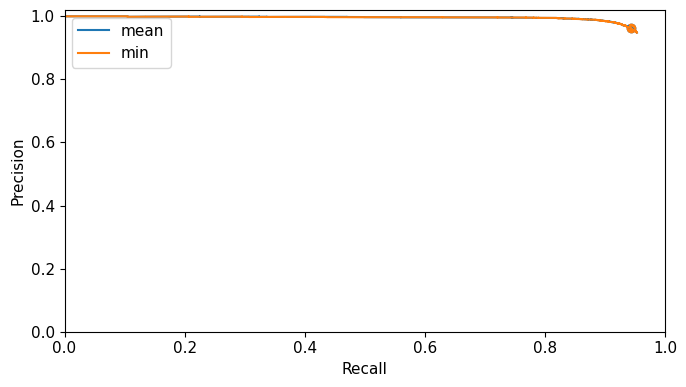

In [ ]:
if '6.5' in BONUS_TASKS:

    def span_pr_curve(gold_tags, pred_tags, word_probs, confidence):
        ranked = []
        n_gold = 0
        for gold, pred, probs in zip(
            gold_tags, pred_tags, word_probs, strict=True
        ):
            targets = set(bio_to_spans(gold))
            n_gold += len(targets)
            for span in bio_to_spans(pred):
                start, end, _ = span
                score = float(confidence(probs[start:end]))
                ranked.append((score, span in targets))

        ranked.sort(key=lambda row: row[0], reverse=True)
        threshold_counts = {}
        n_true = 0
        for n_pred, (threshold, is_true) in enumerate(ranked, start=1):
            n_true += is_true
            threshold_counts[threshold] = (n_pred, n_true)
        threshold_counts[0.0] = (len(ranked), n_true)

        points = []
        for threshold, (n_pred, n_true) in threshold_counts.items():
            points.append(
                {
                    'threshold': threshold,
                    'precision': n_true / n_pred if n_pred else 0.0,
                    'recall': n_true / n_gold if n_gold else 0.0,
                    'f1': (
                        2 * n_true / (n_pred + n_gold)
                        if n_pred + n_gold
                        else 0.0
                    ),
                }
            )
        return points

    confidence_tags, word_probs = predict_word_tags(
        model, val_tokens, return_probs=True
    )
    threshold_results = {}
    figure, axis = plt.subplots(figsize=(7, 4))

    for name, confidence in [('mean', np.mean), ('min', min)]:
        points = span_pr_curve(
            val_gold, confidence_tags, word_probs, confidence
        )
        baseline_point = points[-1]
        best = max(
            points, key=lambda point: (point['f1'], -point['threshold'])
        )
        delta = best['f1'] - baseline_point['f1']
        threshold_results[name] = {
            'best': best,
            'threshold_zero': baseline_point,
            'delta_f1': delta,
        }
        print(
            f"{name}: threshold {best['threshold']:.4f}, "
            f"F1 {best['f1']:.4f}, прирост {delta:+.4f}"
        )
        axis.step(
            [0.0] + [point['recall'] for point in points],
            [1.0] + [point['precision'] for point in points],
            where='post',
            label=name,
        )
        axis.scatter(best['recall'], best['precision'])

    axis.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
    axis.legend()
    figure.tight_layout()
    plt.show()
    bonus_results['6.5'] = threshold_results

if bonus_results:
    metrics['bonuses'] = bonus_results
    (ARTIFACTS / 'metrics.json').write_text(
        json.dumps(json_ready(metrics), ensure_ascii=False, indent=2),
        encoding='utf-8',
    )

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ**

Уверенность спана считается двумя способами: средняя вероятность
по его словам и минимальная вероятность. Минимум сильнее реагирует
на одно неуверенное слово, среднее сглаживает его вклад.
Лучший порог для каждого способа выбирается на validation,
а рядом печатается прирост к порогу 0. Фильтр только убирает
предсказанные спаны, поэтому число верно найденных сущностей
и recall могут только уменьшиться или остаться прежними